# Task 1: hand-code gradient descent on f(x)=(x-3)^2; plot loss

**Plan**

define loss(x)
define gradient(x)

x = starting value

lr = learning rate

losses = empty list

repeat N times:
    
    save loss(x) into losses
    g = gradient(x)
    x = x minus lr times g

plot losses

print final x

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import math

x_initial=0.0
lrs = [0.01, 0.1, 0.5, 0.9, 1.0, 1.1]
steps = 300
losses = {}
x_path = {}

In [2]:
def loss(x):
    f_x= (x-3)**2
    return f_x

def derivative(x):
    df_x = 2*(x - 3)
    return df_x
    
def gradient_descent(x,lr):
    losses[lr] = []
    x_path[lr] = []
    for i in range(steps):
        l = loss(x)
        x_path[lr].append(x)
        losses[lr].append(l)
        x = x - (lr * derivative(x))
        
    return x
    
def plot_results(result, steps, label):
    step = list(range(steps))
    num_plots = len(result)
    col = math.ceil(math.sqrt(num_plots))
    row = -(num_plots // -col) #same as ceil(num_plots/col)
    fig, axs = plt.subplots(row, col, figsize=(25,10)) 
    keys = list(result)
    for i in range (row):
        for j in range (col):
            key_pos = (i * col) + j
            key = keys[key_pos]
            axs[i][j].set_xlabel("Step")
            axs[i][j].set_ylabel(label)
            axs[i][j].set_title(f"GDS: lr={key}")
            #ax.set_yscale("log")
            axs[i][j].plot(step,result[key])
    plt.tight_layout() 
    plt.show()
    
#new version
def plot_2(result,label):
    num_plots = len(result)
    col = math.ceil(math.sqrt(num_plots))
    row = -(num_plots // -col) #same as ceil(num_plots/col)
    fig, axs = plt.subplots(row, col, figsize=(25,10)) 
    axs = np.atleast_1d(axs).flatten()
    for ax, key in zip(axs, result):
        ax.plot(result[key])
        ax.set_title(f"lr={key}")
        ax.set_xlabel("Step")
        ax.set_ylabel(label)
    for ax in axs[len(result):]:
        ax.axis("off")   # hide unused panels
        

In [3]:
print(f"Steps:{steps}")
for lr in lrs:
    x = x_initial
    x = gradient_descent(x,lr)
    print(f"Learning rate : {lr}, final x:{x}")


Steps:300
Learning rate : 0.01, final x:2.993002482996146
Learning rate : 0.1, final x:2.999999999999999
Learning rate : 0.5, final x:3.0
Learning rate : 0.9, final x:2.999999999999999
Learning rate : 1.0, final x:0.0
Learning rate : 1.1, final x:-1.7040999708023472e+24


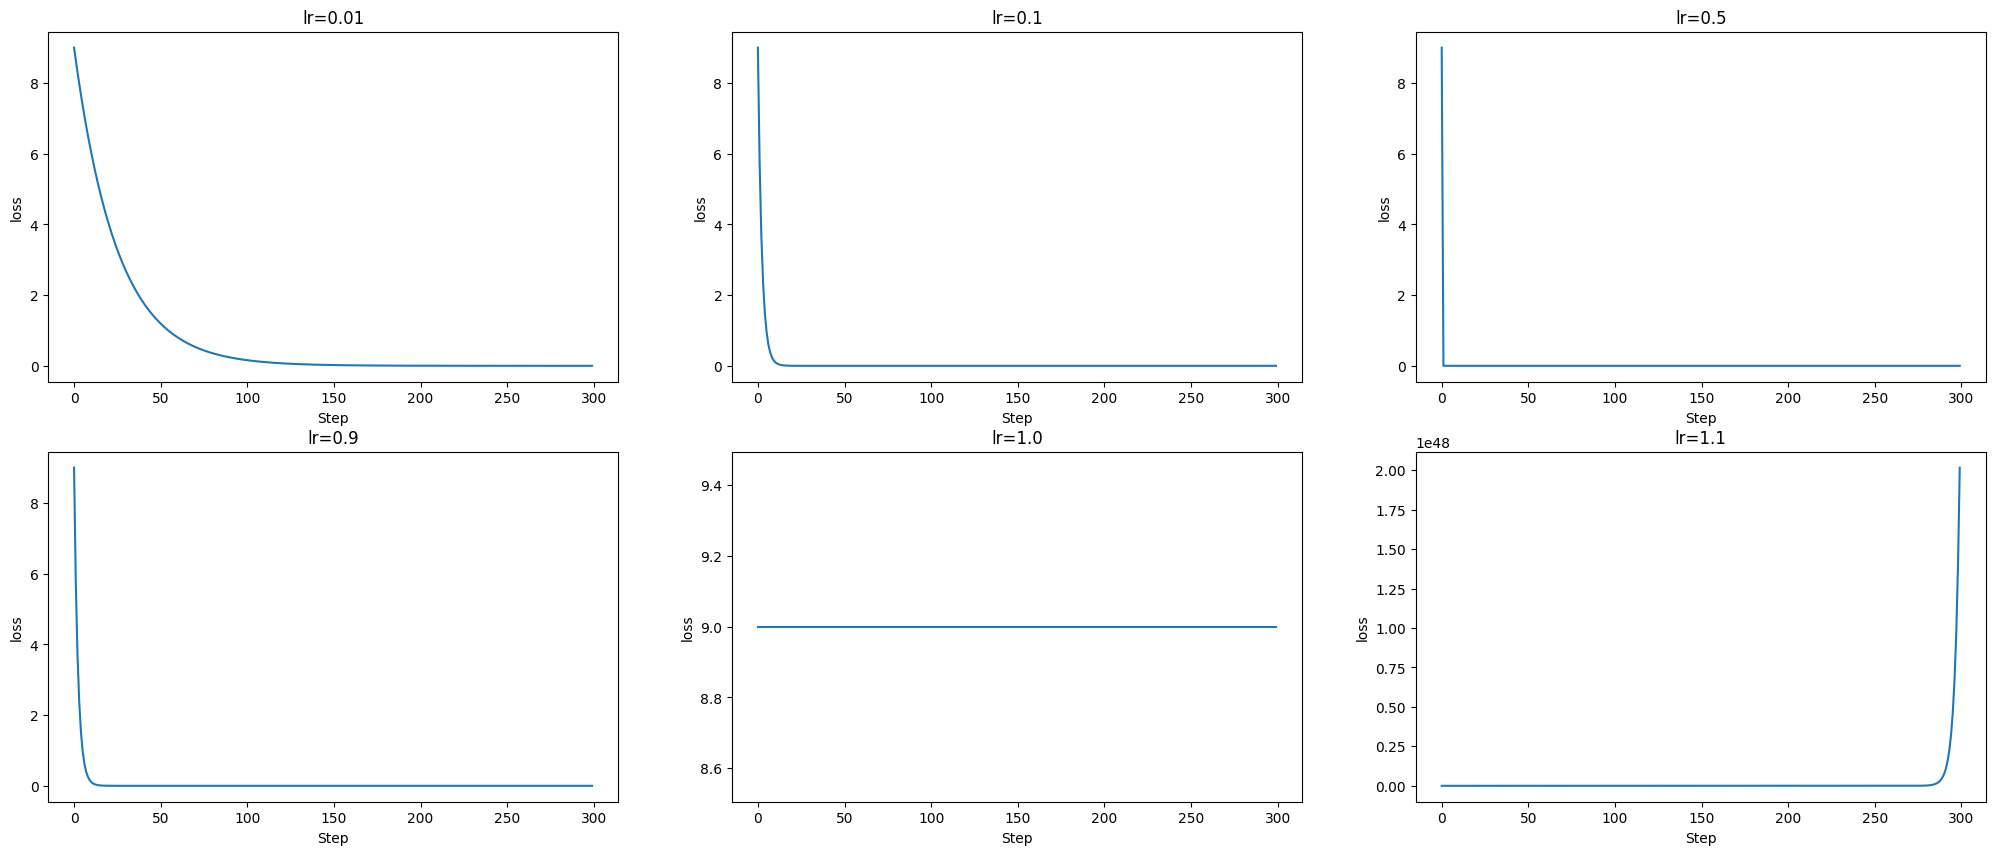

In [4]:
plot_2(losses,"loss")

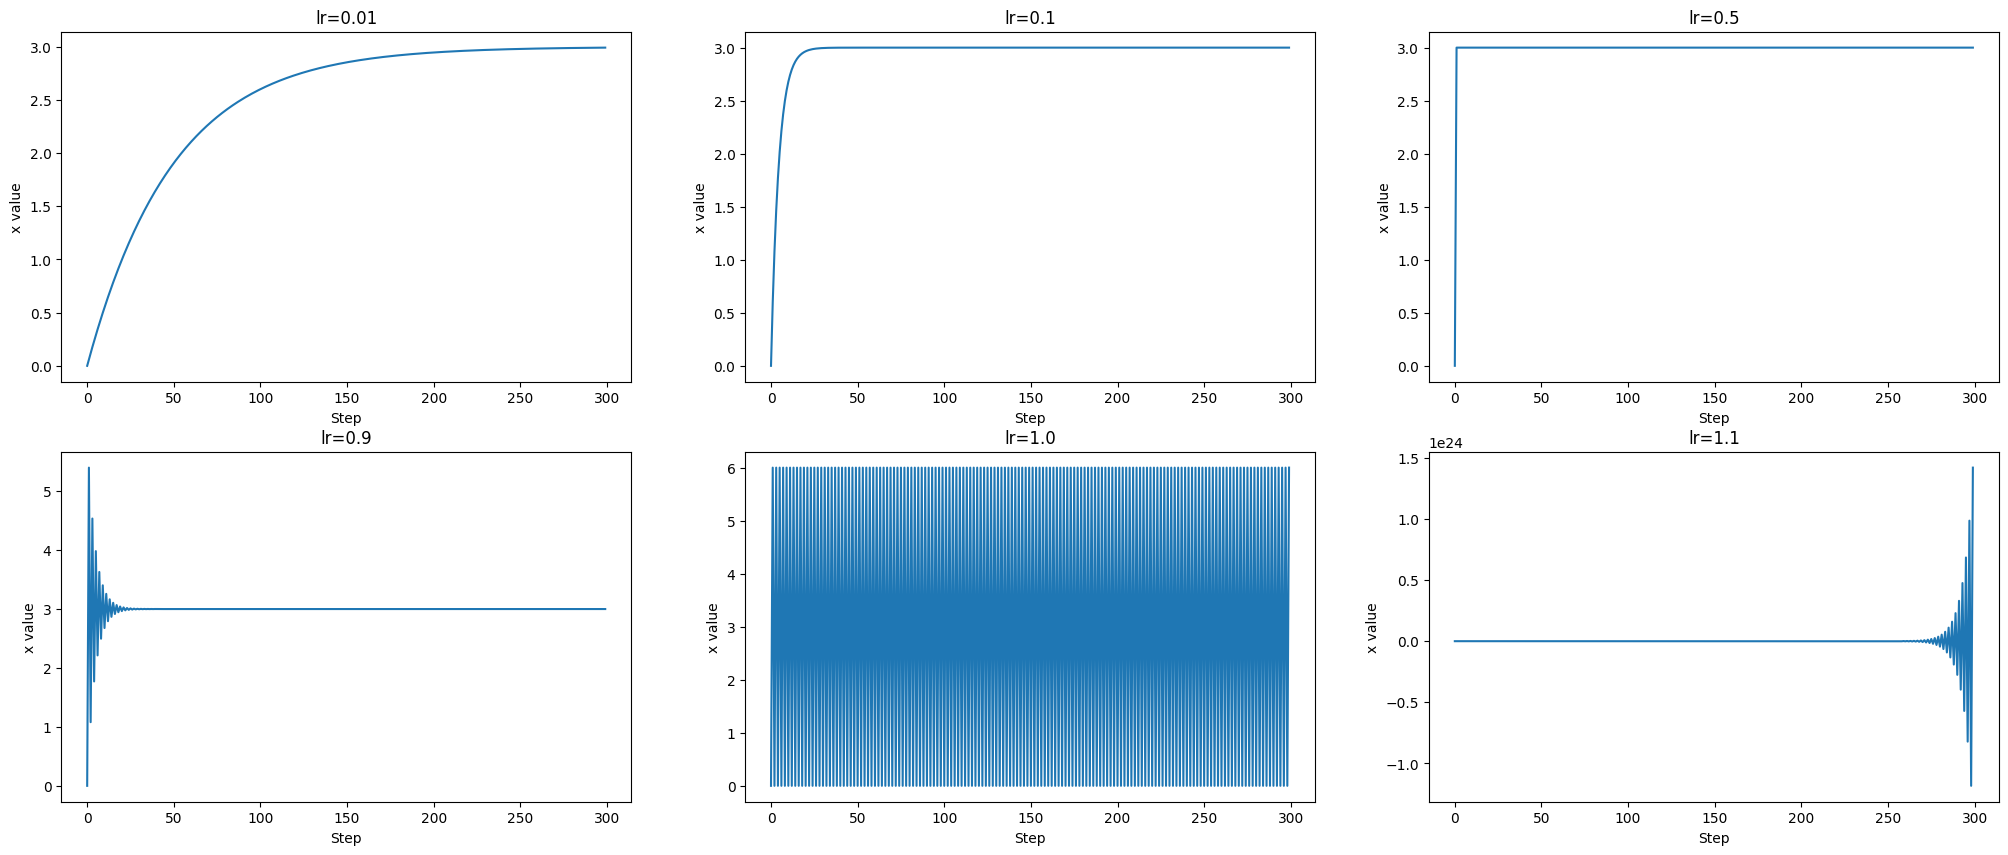

In [5]:
#seeing how x moves along
plot_2(x_path,"x value")